In [2]:

import matplotlib.gridspec as gridspec
import os
import sys

import umap

active_lambda = 0.1 # Default value if not imported
sys.path.append(os.path.abspath('../../'))
from BWM.ScriptsandFunctions.bwm_functions import *
plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

# Set global plotting parameters for font size
tick_fontsize = 6
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': tick_fontsize,
    'ytick.labelsize': tick_fontsize,
    'legend.fontsize': 7,
    'figure.titlesize': 7
})

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


Using device: cpu


In [3]:
def iso_ae_preprocessing(pseudo_response_tensor):
    """
    Preprocess neural responses intro response matrix (n x kt) for autoencoder.
    """
    response_tensor = np.mean(pseudo_response_tensor, axis=0)
    # Z-score and reshape
    response_tensor_norm = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    response_matrix = response_tensor_norm.reshape(-1, response_tensor_norm.shape[2])
    X_transposed = response_matrix.T
    # Scale each row (neuron) to unit length
    #row_norms = np.linalg.norm(X_transposed, axis=1, keepdims=True)
    #X_pre_pca = X_transposed / (row_norms + 1e-8)
    return X_transposed


# directory_path='../Data2'
# eids = [d for d in os.listdir(directory_path) if os.path.isdir(os.path.join(directory_path, d))]
# result = get_region_response_matrix(
#                 region=['MOs','MOp'],
#                 eids=eids,
#                 directory_path=directory_path,
#                 event="stimOn_times",
#                 conditions=['choice'],
#                 n_pseudo=25,
#                 threshold=1,
#                 std_above=50,
#                 std_below=50,
#                 filter_significant=False,
#                 n_steps=100,
#                 step=0.01,
#                 sigma=2,
#                 mapping='Beryl'
#             )
# pseudo_response_tensor =result[0]
pseudo_response_tensor = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/ResponseData/CP_pseudo_responses.npy')
# pseudo_response_tensor = pseudo_response_tensor[:,:,:,np.mean(pseudo_response_tensor,axis=(0,1,2))<15]



In [4]:
def trial_variability(x):

    z = (x-np.mean(x,axis=(0,1,2)))/np.std(x,axis=(0,1,2))
    return (
        np.mean(np.std(z, axis=0),axis=(0,1)))

variability = trial_variability(pseudo_response_tensor)
pseudo_response_tensor=pseudo_response_tensor[:,:,:,variability<.7]

X_input = iso_ae_preprocessing(pseudo_response_tensor)


In [5]:
def calculate_msd_data(response_tensor):
    """
    Calculate Mean Standardized Derivative using finite differences.
    responses: (conditions, time, neurons)
    """
    z = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    speed= np.mean(np.abs(np.diff(z,axis=1)),axis=(0,1))

    return speed

msd_data = calculate_msd_data(np.mean(pseudo_response_tensor, axis=0))

<Axes: >

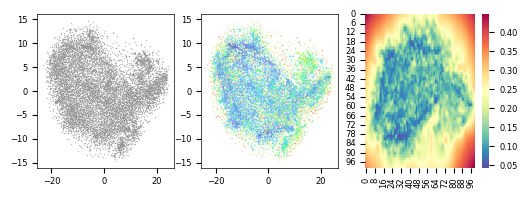

In [9]:
# Plot densmap projection of EID responses
#Figure 1
fig = plt.figure(figsize=(6, 2))
gs = gridspec.GridSpec(1, 3)
ax1 = plt.subplot(gs[0,0])
ax2 = plt.subplot(gs[0,1])
ax3 = plt.subplot(gs[0,2])
# First row
from sklearn.manifold import TSNE
#z_neurons = umap.UMAP(densmap = True, dens_lambda=2, n_neighbors=500).fit_transform(X_input)
z_neurons = TSNE( perplexity=500).fit_transform(X_input)
sns.scatterplot(x = z_neurons[:,0], y= z_neurons[:,1], color = 'gray',ax=ax1,s=1,legend=False,alpha =.5)
sns.scatterplot(x = z_neurons[:,0], y= z_neurons[:,1], hue = msd_data,ax=ax2,palette='turbo',s=1,alpha = .5,legend=False)

from scipy.interpolate import Rbf

# Calculate limits for plotting based on the initial state
x_min, x_max = z_neurons[:,0].min(), z_neurons[:,0].max()
y_min, y_max = z_neurons[:,1].min(), z_neurons[:,1].max()
pad = 0.5

# Prepare RBF background
grid_x, grid_y = np.mgrid[x_min-pad:x_max+pad:100j, y_min-pad:y_max+pad:100j]
rbf = Rbf(z_neurons[:,0], z_neurons[:,1], msd_data, function='multiquadric', smooth=1)
grid_msd = rbf(grid_x, grid_y)
sns.heatmap(grid_msd.T,ax=ax3,cmap='Spectral_r')


In [29]:
class RNN(torch.nn.Module):
    def __init__(self, n, input_dim, beta, bias):
        super(RNN, self).__init__()
        self.n = n
        self.input_dim = input_dim
        self.beta = beta
        self.bias = bias
        self.activation = torch.nn.Softplus(beta=self.beta)
        self.recurrent_layer = nn.Linear(self.n, self.n, bias=True)
        self.recurrent_layer.bias.data.normal_(mean=self.bias, std=0)
        self.recurrent_layer.bias.requires_grad = True
        self.input_layer = nn.Linear(self.input_dim, self.n, bias=False)

        self.alpha = .1
    def forward(self, u, dt, steps):
        batch_size = u.shape[0]
        states = torch.zeros(batch_size, 1, self.n, device=device)
        for i in range(steps - 1):
            state_new = (1 - self.alpha * dt) * states[:, i, :] + self.alpha *dt * (
                self.activation(self.recurrent_layer(states[:, i, :]) + self.input_layer(u)))
            states = torch.cat((states, state_new.unsqueeze_(1)), 1)
        return states


n_neurons = pseudo_response_tensor.shape[3]

# net = torch.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/ScriptsandFunctions/RNN.pth',weights_only=False,map_location=torch.device('cpu'))

In [30]:
lr = .0002
steps=100
active_lambda=0.01
bias = 2
beta = 1
dt = 1
n_neurons = pseudo_response_tensor.shape[3]
net = RNN(n=n_neurons, input_dim=1, beta=beta, bias=bias).to(device)
u = torch.FloatTensor(np.linspace(-1, 1, 2)).to(device)
optimizer = optim.Adam(net.parameters(), lr=lr)
criterion = nn.MSELoss()
net.train()
print("Training RNN...")
for epoch in range(2000):
    optimizer.zero_grad()
    x = net(u.unsqueeze(1), dt, steps)
    x_norm = (x - torch.mean(x, dim=(0,1), keepdim=True)) / (torch.std(x, dim=(0,1), keepdim=True) + 1e-8)
    x_norm = x_norm.reshape(-1, x_norm.shape[2]).T
    activity_penalty = torch.std(torch.mean(x, dim=(0,1))) +  torch.std(torch.std(x, dim=(0,1)))
    # x_norm = (x_reshaped - torch.mean(x_reshaped, dim=1, keepdim=True)) / (torch.std(x_reshaped, dim=1, keepdim=True) + 1e-8)

    loss = criterion(torch.FloatTensor(X_input).to(device), x_norm) + active_lambda * activity_penalty

    loss.backward()
    optimizer.step()
    if epoch % 10 == 0:
        y_true = torch.FloatTensor(X_input).to(device)
        y_pred = x_norm

        # Mean across neurons (dim 0 of X_input is n_neurons)
        # y_true and y_pred are (n_neurons, features)
        ss_res = torch.sum((y_true - y_pred)**2, dim=1)
        ss_tot = torch.sum((y_true - torch.mean(y_true, dim=1, keepdim=True))**2, dim=1)
        r2 = 1 - ss_res / (ss_tot + 1e-8)
        mean_r2 = torch.mean(r2).item()
        print(f"Epoch {epoch}: Loss = {loss.item():.4f} |  R2 = {mean_r2:.4f}")

Training RNN...
Epoch 0: Loss = 1.7432 |  R2 = -0.7302
Epoch 10: Loss = 0.9556 |  R2 = 0.0890
Epoch 20: Loss = 0.6736 |  R2 = 0.3549
Epoch 30: Loss = 0.5640 |  R2 = 0.4622
Epoch 40: Loss = 0.5026 |  R2 = 0.5178
Epoch 50: Loss = 0.4655 |  R2 = 0.5523
Epoch 60: Loss = 0.4353 |  R2 = 0.5817
Epoch 70: Loss = 0.4107 |  R2 = 0.6051
Epoch 80: Loss = 0.4053 |  R2 = 0.6098
Epoch 90: Loss = 0.3819 |  R2 = 0.6325
Epoch 100: Loss = 0.3671 |  R2 = 0.6465
Epoch 110: Loss = 0.3536 |  R2 = 0.6598
Epoch 120: Loss = 0.3479 |  R2 = 0.6653
Epoch 130: Loss = 0.3362 |  R2 = 0.6763
Epoch 140: Loss = 0.3272 |  R2 = 0.6851
Epoch 150: Loss = 0.3220 |  R2 = 0.6903
Epoch 160: Loss = 0.3123 |  R2 = 0.6996
Epoch 170: Loss = 0.3042 |  R2 = 0.7074


KeyboardInterrupt: 

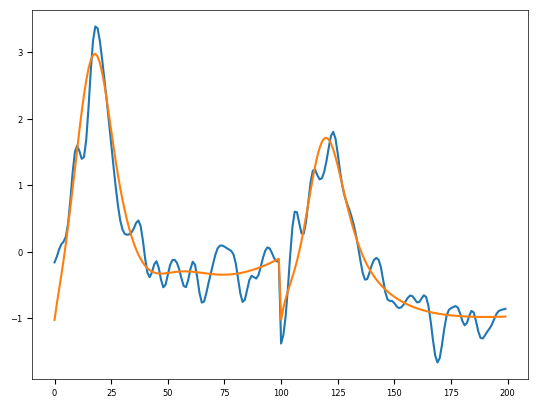

In [31]:
plt.figure()
x = net(u.unsqueeze(1), dt, steps)
x_norm = (x - torch.mean(x, dim=(0,1), keepdim=True)) / (torch.std(x, dim=(0,1), keepdim=True) + 1e-8)
x_norm = x_norm.reshape(-1, x_norm.shape[2]).T
plt.plot(X_input[1,:])
plt.plot(x_norm[1,:].detach().numpy())

<Axes: >

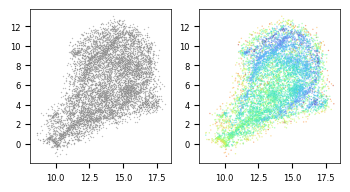

In [32]:
fig = plt.figure(figsize=(4, 2))
gs = gridspec.GridSpec(1, 2)
ax1 = plt.subplot(gs[0,0])
ax2 = plt.subplot(gs[0,1])

from sklearn.manifold import TSNE
# First row


X_rnn = net(u.unsqueeze(1), dt, 100)
X_rnn = (X_rnn - torch.mean(X_rnn, dim=(0,1), keepdim=True)) / (torch.std(X_rnn, dim=(0,1), keepdim=True) + 1e-8)
X_rnn_reshaped = X_rnn.reshape(-1, X_rnn.shape[2]).T.detach().cpu().numpy()
speed_rnn_original = torch.mean(torch.abs(torch.diff(X_rnn,dim=1)),dim=(0,1)).detach()

z_neurons = umap.UMAP(densmap = True, dens_lambda=2, n_neighbors=500).fit_transform(X_rnn_reshaped)
sns.scatterplot(x = z_neurons[:,0], y= z_neurons[:,1], color = 'gray',ax=ax1,s=1,legend=False,alpha =.5)

sns.scatterplot(x = z_neurons[:,0], y= z_neurons[:,1], hue = speed_rnn_original,ax=ax2,palette='turbo',s=1,alpha=.5,legend=False)


In [ ]:
X_rnn_reshaped.shape

In [33]:
# Fit MLP model of densmap projections
import torch
import torch.nn as nn
import torch.optim as optim

class TensorTransformer(nn.Module):
    def __init__(self, input_dim, output_dim, dropout_rate=0.):
        super(TensorTransformer, self).__init__()
        # A simple 3-layer architecture with dropout for robustness
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),    # Input layer to hidden layer 1         # Hidden layer 1 t
            nn.ReLU(),
            nn.Linear(64, 64),    # Input layer to hidden layer 1         # Hidden layer 1 t
            nn.ReLU(),    # Non-linear activation  # Dropout for regularization
            nn.Linear(64, output_dim)    # Hidden layer 2 to output layer
        )

    def forward(self, x, noise_std=1):
        # Add Gaussian noise to input during training for better generalization
        if self.training and noise_std > 0:
            noise = torch.randn_like(x) * noise_std
            x = x + noise
        return self.network(x)

epochs = 100000
learning_rate = 0.001

y = net(u = u.unsqueeze(1),dt=dt,steps=100).detach()
z = (y - torch.mean(y,dim=(0,1)))/torch.std(y,dim=(0,1))
x = z.reshape(-1,z.shape[2]).t()

y = torch.FloatTensor(umap.UMAP(densmap=True,dens_lambda=2,n_neighbors=500).fit_transform(x))


# Initialize model, loss function, and optimizer
densMAPprojector = TensorTransformer(input_dim=x.shape[1], output_dim=2)
criterion = nn.MSELoss()
optimizer = optim.Adam(densMAPprojector.parameters(), lr=learning_rate)

# Put model in training mode
densMAPprojector.train()

for epoch in range(epochs):
    # 1. Forward pass: compute predicted y by passing x to the model
    predictions = densMAPprojector(x)

    # 2. Compute loss
    loss = criterion(predictions, y)

    # 3. Zero gradients, perform a backward pass, and update the weights
    optimizer.zero_grad()  # Clear old gradients
    loss.backward()        # Backpropagation
    optimizer.step()       # Gradient descent step

    # Print progress every 20 epochs
    if (epoch + 1) % 1000 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}")

Epoch [1000/100000], Loss: 0.7742
Epoch [2000/100000], Loss: 0.3313
Epoch [3000/100000], Loss: 0.2813
Epoch [4000/100000], Loss: 0.2293
Epoch [5000/100000], Loss: 0.2474
Epoch [6000/100000], Loss: 0.2083
Epoch [7000/100000], Loss: 0.1944
Epoch [8000/100000], Loss: 0.2050
Epoch [9000/100000], Loss: 0.1982
Epoch [10000/100000], Loss: 0.1920
Epoch [11000/100000], Loss: 0.1839


KeyboardInterrupt: 

<Axes: xlabel='None', ylabel='None'>

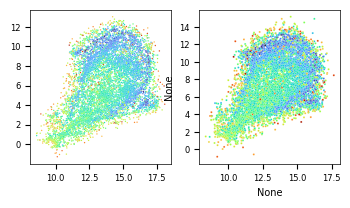

In [34]:
#Figure 1
fig = plt.figure(figsize=(4, 2))
gs = gridspec.GridSpec(1, 2)
ax1 = plt.subplot(gs[0,0])
ax2 = plt.subplot(gs[0,1])
densMAPprojector.eval()
# First row
X_rnn = net(u = u.unsqueeze(1),dt=dt,steps=100)
X_rnn = (X_rnn - torch.mean(X_rnn,dim = (0,1),keepdim=True))/torch.std(X_rnn,dim = (0,1),keepdim = True)
speed_rnn_original = torch.mean(torch.abs(torch.diff(X_rnn,dim=1)),dim=(0,1)).detach()

X_rnn_reshaped = X_rnn.detach().permute(2, 0, 1).reshape(X_rnn.shape[2], -1)
#z_neurons = umap.UMAP(densmap=True,dens_lambda=2,n_neighbors=500).fit_transform(X_rnn_reshaped)

sns.scatterplot(x = z_neurons[:,0], y= z_neurons[:,1], hue = speed_rnn_original,ax=ax1,palette='turbo',s=1,legend=False)
z_neurons_mimic = densMAPprojector(X_rnn_reshaped).detach()
sns.scatterplot(x = z_neurons_mimic[:,0], y= z_neurons_mimic[:,1], hue = speed_rnn_original,ax=ax2,palette='turbo',s=2,legend=False)



In [35]:
# Retraining


def efficient_variance_explained_svd_vals(responses,top_k):
    x_centered = responses - responses.mean(dim=(0),keepdim=True)
    S = torch.linalg.svdvals(x_centered)
    eigenvalues = S**2
    actual_k = min(top_k,len(eigenvalues))
    return eigenvalues[:actual_k]/eigenvalues.sum()

top_k = 100
steps = 100
# Get eigenvalues for original RNN
y = net(u.unsqueeze(1),dt,steps)
# eigs = torch.sort(torch.real(
#     torch.linalg.eigvals(torch.cov(y.reshape(-1, y.shape[2]).t()))),
#                   descending=True)[0]
#
# target
#target_fve = (eigs/ torch.sum(eigs)).detach()
z = (y - torch.mean(y,dim=(0,1)))/torch.std(y,dim=(0,1))
msd_rnn = torch.mean(torch.abs(torch.diff(z,dim=1)),dim=(0,1))
target_fve = efficient_variance_explained_svd_vals(y.reshape(-1, y.shape[2]).t(),top_k = top_k).detach()

In [42]:

# net_contract = torch.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/CP_net.pth',weights_only=False,map_location=torch.device('cpu'))
#net_contract = torch.load('net.pth',weights_only=False,map_location=torch.device('cpu'))
import copy


# 1. Instantiate the cloned architecture

net_contract = RNN(n=net.n, input_dim=1, beta=beta, bias=bias).to(device)
# 2. Copy the state weights into the clone
net_contract.load_state_dict(copy.deepcopy(net.state_dict()))

#u = torch.FloatTensor(np.linspace(-1, 1, 3)).to(device)
optimizer = optim.Adam(net_contract.parameters(), lr=.00001)
criterion = nn.MSELoss()
steps = 100
# pca = PCA()
# x = net(u.unsqueeze(1),dt,steps)
# z = (x-torch.mean(x,dim=(0,1))) / torch.std(x,dim=(0,1))
# pca.fit(z.reshape(-1,z.shape[2]).t().detach().numpy())

In [43]:
import torch

import torch

# Contraction training

threshold = .025
densMAPprojector.eval()
# Allocate lists for projections and speed
projections = []
speeds = []
prev_projection = None
#curvature_target = fsecond(torch.linspace(0,100,100),shift= 20, scale = 2,height = 3)
for epoch in range(5000):
    optimizer.zero_grad()
    x = net_contract(u.unsqueeze(1),dt,steps)


    # Activity penalty
    mean_activities = x.mean(dim=(0, 1))
    activity_penalty = mean_activities.std()

    # Variance penalty
    fve = efficient_variance_explained_svd_vals(x.reshape(-1, x.shape[2]).t(),top_k = top_k)
    variance_penalty = torch.mean((fve-target_fve)**2)
    #variance_penalty = torch.mean(fve[3:])

    # Speed penalty
    z = (x-torch.mean(x,dim=(0,1))) / torch.std(x,dim=(0,1))
    speed = torch.mean(torch.abs(torch.diff(z,dim=1)),dim=(0,1))
    #speed=soft_median(torch.abs(torch.diff(z,dim=1)))

    #speed,_ = soft_median(torch.abs(torch.diff(z,dim=1)).flatten(start_dim=0, end_dim=1),dim=0)
    speed_penalty = torch.mean(speed)

    curr_projection = densMAPprojector(z.reshape(-1,z.shape[2]).t())

    # Change penalty (encourages changes in projections between epochs to decrease)
    if prev_projection is not None:
        change_penalty = nn.MSELoss()(curr_projection, prev_projection)
    else:
        change_penalty = torch.tensor(0.0).to(device)

    # Penalize speed in densmap projection
    
    # Response penalty
    X_rnn_reshaped = X_rnn.detach().permute(2, 0, 1).reshape(X_rnn.shape[2], -1)
    x_reshaped = x.reshape(-1, x.shape[2]).T
    x_norm = (x_reshaped - torch.mean(x_reshaped, dim=1, keepdim=True)) / (torch.std(x_reshaped, dim=1, keepdim=True) + 1e-8)
    response_penalty = nn.MSELoss()(X_rnn_reshaped[speed_rnn_original<.03,:], x_norm[speed_rnn_original<.03,:])

    # Linear mapping penalty (encourages mapping from prev to curr to be linear)
    if prev_projection is not None:
        # We want to find A, b such that curr \approx prev @ A + b
        # Prepare prev with a column of ones for bias
        X = torch.cat([prev_projection, torch.ones(prev_projection.shape[0], 1).to(device)], dim=1)
        Y = curr_projection
        # Solve for A_hat using least squares: X @ A_hat = Y
        # A_hat will have shape (3, 2)
        try:
            A_hat = torch.linalg.lstsq(X, Y).solution
            linear_fit = X @ A_hat
            linear_mapping_penalty = nn.MSELoss()(Y, linear_fit)
        except:
            linear_mapping_penalty = torch.tensor(0.0).to(device)
    else:
        linear_mapping_penalty = torch.tensor(0.0).to(device)

    # Calculate loss and backpropagate
    # Adding change_penalty with a weight that increases toward the end of training
    change_weight = 1 * (epoch / 1000)
    loss =  0*variance_penalty + 0*activity_penalty + 1 * speed_penalty# +0*response_penalty + 0. * linear_mapping_penalty #+ change_weight * change_penalty
    #loss =  activity_penalty
    loss.backward()
    optimizer.step()
    speeds.append(speed.detach())
    projections.append(curr_projection)
    prev_projection = curr_projection.detach()

    if epoch % 1 == 0:
        print(f"Epoch {epoch}: Loss = {loss.item():.4f} | variance = {variance_penalty.item():.4f} | active = {activity_penalty.item():.4f} | speed = {speed_penalty.item():.4f} | linear = {linear_mapping_penalty.item():.4f} | change = {change_penalty.item():.4f}   ")


Epoch 0: Loss = 0.0622 | variance = 0.0000 | active = 0.6933 | speed = 0.0622 | linear = 0.0000 | change = 0.0000   
Epoch 1: Loss = 0.0597 | variance = 0.0000 | active = 0.7137 | speed = 0.0597 | linear = 0.0949 | change = 0.0967   
Epoch 2: Loss = 0.0573 | variance = 0.0000 | active = 0.7412 | speed = 0.0573 | linear = 0.0905 | change = 0.0922   
Epoch 3: Loss = 0.0551 | variance = 0.0001 | active = 0.7740 | speed = 0.0551 | linear = 0.0934 | change = 0.0951   
Epoch 4: Loss = 0.0529 | variance = 0.0002 | active = 0.8108 | speed = 0.0529 | linear = 0.0860 | change = 0.0880   
Epoch 5: Loss = 0.0509 | variance = 0.0002 | active = 0.8509 | speed = 0.0509 | linear = 0.0829 | change = 0.0855   
Epoch 6: Loss = 0.0490 | variance = 0.0003 | active = 0.8937 | speed = 0.0490 | linear = 0.0743 | change = 0.0771   
Epoch 7: Loss = 0.0472 | variance = 0.0004 | active = 0.9390 | speed = 0.0472 | linear = 0.0805 | change = 0.0836   
Epoch 8: Loss = 0.0455 | variance = 0.0005 | active = 0.9861 | s

KeyboardInterrupt: 

In [44]:
                # data = torch.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/projections.pth',map_location=torch.device('cpu')).detach().numpy()
data = torch.stack(projections).detach().numpy()
#data = np.stack(projections)
speeds_np = torch.stack(speeds).detach().cpu().numpy()
vmin_speed = speeds_np.min()
vmax_speed = speeds_np.max()

# Pick 50 neurons with high msd for trajectories
top_50_indices = np.argsort(msd_data)[-50:]
start_points = data[0, top_50_indices, :]
end_points = data[-1, top_50_indices, :]

# Pick a random neuron from the top 50 to highlight its full path
random_high_msd_idx = np.random.choice(top_50_indices)
highlight_trajectory = data[:, random_high_msd_idx, :]


In [39]:
projections[0].shape

torch.Size([8644, 2])

In [40]:
import matplotlib.animation as animation
from IPython.display import HTML

# Create a video of 'data' evolution
fig_anim, ax_anim = plt.subplots(figsize=(5, 5))

# Use the same limits as the streamline plot for consistency
x_min_anim, x_max_anim = data[:, :, 0].min(), data[:, :, 0].max()
y_min_anim, y_max_anim = data[:, :, 1].min(), data[:, :, 1].max()
padding = 0.1
x_min_anim -= padding * (x_max_anim - x_min_anim)
x_max_anim += padding * (x_max_anim - x_min_anim)
y_min_anim -= padding * (y_max_anim - y_min_anim)
y_max_anim += padding * (y_max_anim - y_min_anim)

ax_anim.set_xlim(x_min_anim, x_max_anim)
ax_anim.set_ylim(y_min_anim, y_max_anim)
ax_anim.axis('off')

# Scatter plot object to update
scat = ax_anim.scatter([], [], marker='.', alpha=1, c=[], cmap='turbo', s=4, vmin=vmin_speed, vmax=vmax_speed)

def init():
    scat.set_offsets(np.empty((0, 2)))
    return (scat,)

def update(frame):
    current_data = data[frame, :, :]
    scat.set_offsets(current_data)
    # Use speeds_np[0] for constant coloring across frames
    scat.set_array(speeds_np[0])
    
    return (scat,)
ani = animation.FuncAnimation(fig_anim, update, frames=len(data),
                              init_func=init, blit=True, interval=50)

# Save the animation
os.makedirs('../Movies', exist_ok=True)

ani.save('../Movies/contraction_evolution.mp4', writer='ffmpeg', fps=20)

plt.close(fig_anim)
HTML(ani.to_jshtml()) # Uncomment to di
# splay in notebook

KeyboardInterrupt: 

/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_51365/4061192792.py:25: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('turbo')


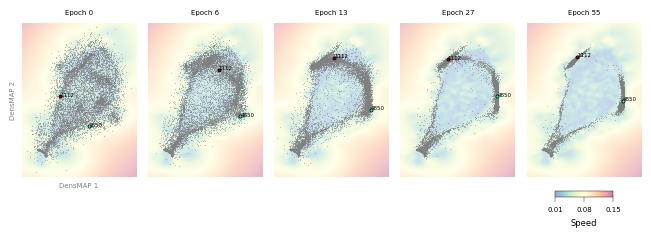

In [45]:
# Visualize the evolution of data in the embedding space
import matplotlib.cm as cm
import matplotlib.colors as colors
from scipy.interpolate import Rbf

# Calculate limits for plotting based on the initial state
x_min, x_max = data[0, :, 0].min(), data[0, :, 0].max()
y_min, y_max = data[0, :, 1].min(), data[0, :, 1].max()
pad = 0.5

# Prepare RBF background
grid_x, grid_y = np.mgrid[x_min-pad:x_max+pad:100j, y_min-pad:y_max+pad:100j]
rbf = Rbf(data[0, :, 0], data[0, :, 1], msd_data, function='multiquadric', smooth=4)
grid_msd = rbf(grid_x, grid_y)

# Choose one high-speed and one medium-speed neuron to highlight
num_neurons = data.shape[1]
sorted_speed_indices = np.argsort(speeds_np[0])
high_speed_idx = sorted_speed_indices[-1] # Fastest neuron
medium_speed_idx = sorted_speed_indices[num_neurons // 2 -100] # Medium speed neuron
highlight_neuron_indices = [high_speed_idx, medium_speed_idx]

# Define colormap and normalization for speeds
norm = colors.Normalize(vmin=speeds_np.min(), vmax=speeds_np.max())
cmap = cm.get_cmap('turbo')
h_colors = [cmap(norm(speeds_np[0, idx])) for idx in highlight_neuron_indices]

# Actual trajectories for the highlighted neurons
actual_trajectories_highlight = data[:, highlight_neuron_indices, :]

fig, axes = plt.subplots(1, 5, figsize=(8, 2))

# Define time points to display (e.g., concentrated at the beginning)
num_subplots = 5
T = data.shape[0] - 1
time_indices = np.array([0, T // 8, T // 4, T // 2, T]).astype(int)

for i, t_idx in enumerate(time_indices):
    ax = axes[i]
    
    # Plot background RBF estimate of msd values
    ax.imshow(grid_msd.T, extent=(x_min-pad, x_max+pad, y_min-pad, y_max+pad), origin='lower', cmap='Spectral_r', alpha=0.3, zorder=0, aspect='auto')
    
    # Plot all neurons at the current time point
    sns.scatterplot(x=data[t_idx, :, 0], y=data[t_idx, :, 1], color='gray', s=.5, alpha=.5, ax=ax, legend=False, edgecolor=None)
    
    # Plot highlighted neurons' current positions
    for h_i, h_idx in enumerate(highlight_neuron_indices):
        sns.scatterplot(x=[actual_trajectories_highlight[t_idx, h_i, 0]], y=[actual_trajectories_highlight[t_idx, h_i, 1]], color=h_colors[h_i], s=5, edgecolor='black', zorder=5, linewidth=.5, ax=ax, legend=False)
        ax.text(actual_trajectories_highlight[t_idx, h_i, 0], actual_trajectories_highlight[t_idx, h_i, 1], f'{h_idx}', fontsize=4, color='k')
    
    # Set axis limits
    ax.set_xlim(x_min - pad, x_max + pad)
    ax.set_ylim(y_min - pad, y_max + pad)
    
    # Overlay data[t,:,:] colored by speeds_np[t]
   

    ax.set_title(f'Epoch {t_idx}',color='k',fontsize = 5)
    if i == 0:
        ax.set_xlabel('DensMAP 1',fontsize = 5,color='gray')
    else:
        ax.set_xlabel('')
    if i == 0:
        ax.set_ylabel('DensMAP 2',fontsize = 5,color='gray')
    else:
        ax.set_ylabel('')
    
    ax.set_xticks([])
    ax.set_yticks([])
    sns.despine(ax=ax, top=True, right=True, left=True, bottom=True)

# Increase horizontal space between subplots
fig.subplots_adjust(wspace=.1)

# Add a colorbar for the speeds
# Positioning colorbar horizontally under the last subplot
# Get position of the last subplot
last_ax_pos = axes[-1].get_position()
cbar_ax = fig.add_axes([last_ax_pos.x0 + last_ax_pos.width * 0.25, last_ax_pos.y0 - 0.1, last_ax_pos.width * 0.5, 0.03])
sm = plt.cm.ScalarMappable(cmap='Spectral_r', norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cbar_ax, label='Speed', ticks=np.linspace(speeds_np.min(), speeds_np.max(), 3), alpha=0.5, orientation='horizontal')
cbar.outline.set_linewidth(0.3)
cbar.ax.set_xticklabels([f'{t:.2f}' for t in np.linspace(speeds_np.min(), speeds_np.max(), 3)])
cbar.ax.tick_params(labelsize=5, width=0.3)
cbar.set_label('Speed', fontsize=6)

# Save the figure
os.makedirs('../Figures', exist_ok=True)
plt.savefig('../Figures/evolution.png', bbox_inches='tight', dpi=300)

#plt.tight_layout(rect=[0, 0, 0.92, 1])
plt.show()

In [ ]:
x = net_contract(u.unsqueeze(1),dt,steps)
pca = PCA().fit(z.reshape(-1,z.shape[2]).t().detach().numpy())
z = (x-torch.mean(x,dim=(0,1))) / torch.std(x,dim=(0,1))
z_proj =pca.transform(z.reshape(-1,z.shape[2]).t().detach().numpy())
# z_proj = umap.UMAP(densmap=True,dens_lambda = 2,n_neighbors = 500).fit_transform(z.reshape(-1,z.shape[2]).t().detach().numpy())
plt.figure()
sns.scatterplot(x = z_proj[:,0],y=z_proj[:,3],alpha = .5,s=2)

In [ ]:
# Identify parameters for RNN prediction
# Based on cell 271: u = torch.FloatTensor(np.linspace(-1, 1, 2)).to(device)
u_val = torch.FloatTensor(np.linspace(-1, 1, 2)).to(device)
dt_val = 1
steps_val = 100

# 1. Experimental response (mean across pseudo-trials)
# pseudo_response_tensor shape: (pseudo_trials, conditions, time, neurons)
exp_response = np.mean(pseudo_response_tensor, axis=0) # (conditions, time, neurons)

# 2. Predicted response from the 'net' model
net.eval()
with torch.no_grad():
    # net forward: (u, dt, steps) -> (batch, time, neurons)
    # u should be (2, 1) as seen in cell 271
    pred_response_torch = net(u_val.unsqueeze(1), dt_val, steps_val)
    pred_response = pred_response_torch.cpu().numpy() # (2, 100, neurons)

# 3. Normalize both responses (Z-score over conditions and time for each neuron)
def normalize_response(resp):
    # resp shape: (conditions, time, neurons)
    mean = np.mean(resp, axis=(0, 1), keepdims=True)
    std = np.std(resp, axis=(0, 1), keepdims=True) + 1e-8
    return (resp - mean) / std

exp_response_norm = normalize_response(exp_response)
pred_response_norm = normalize_response(pred_response)

# 4. Select two neurons: one with low MSD and one with high MSD
low_msd_idx = np.argsort(msd_data)[40]
high_msd_idx = np.argsort(msd_data)[-3000]

# 5. Plot the comparison
fig = plt.figure(figsize=(8, 5))
gs = gridspec.GridSpec(2, 2, height_ratios=[1, 2])

# Calculate curvature for all neurons
# pred_curvature shape: (batch, steps, neurons)
pred_curvature, _ = get_curvature(net, u_val.unsqueeze(1), dt_val, steps_val)

# Determine global y-limits for curvature plots
curvature_neurons = [low_msd_idx, high_msd_idx]
c_min = pred_curvature[:, :, curvature_neurons].min()
c_max = pred_curvature[:, :, curvature_neurons].max()
# Add a small buffer
c_range = c_max - c_min
c_min -= 0.05 * c_range
c_max += 0.05 * c_range

for idx, neuron_idx in enumerate(curvature_neurons):
    msd_val = msd_data[neuron_idx]
    title_prefix = "Low MSD" if idx == 0 else "High MSD"
    
    # --- Top Row: Curvature Plot ---
    ax_curv = fig.add_subplot(gs[0, idx])
    # Plot curvature for all conditions
    for c in range(pred_curvature.shape[0]):
        ax_curv.plot(pred_curvature[c, :, neuron_idx], color='green', alpha=0.8)
    
    ax_curv.set_title(f"{title_prefix} Curvature")
    ax_curv.set_ylim(c_min, c_max)
    if idx == 0:
        ax_curv.set_ylabel("$\dot{h}_i^2 f''(h_i)$")
    ax_curv.set_xlabel("Time")
    sns.despine(ax=ax_curv)

    # --- Bottom Row: Response Plot ---
    ax_resp = fig.add_subplot(gs[1, idx])
    
    # Plot experimental response for all conditions
    for c in range(exp_response_norm.shape[0]):
        ax_resp.plot(exp_response_norm[c, :, neuron_idx], color='blue', alpha=0.3, label='Exp' if c==0 else "")
    
    # Plot predicted response for all conditions
    for c in range(pred_response_norm.shape[0]):
        ax_resp.plot(pred_response_norm[c, :, neuron_idx], color='red', linestyle='--', alpha=0.8, label='Net' if c==0 else "")
    
    ax_resp.set_title(f"{title_prefix} Response (Neuron {neuron_idx}, MSD={msd_val:.4f})")
    ax_resp.set_xlabel("Time")
    if idx == 0:
        ax_resp.set_ylabel("Normalized Response")
    ax_resp.legend()
    sns.despine(ax=ax_resp)

plt.tight_layout()
os.makedirs('../Figures', exist_ok=True)
plt.savefig('../Figures/neuron_fit_comparison.png', dpi=300)
plt.show()

In [ ]:
data.shape

In [ ]:
data.shape